<div align="center">

# МГТУ им. Н.Э. Баумана

### Факультет «Информатика и системы управления» (ИУ)
### Кафедра «Информационные системы и телекоммуникации» (ИУ3)

# Отчёт по лабораторной работе №7
## по курсу «Технологии машинного обучения»

### Тема: Введение в методы оптимизации. Условный экстремум

</div>

---

**Выполнил:** Суржиков Лев Алексеевич

**Группа:** ИУ3С-51Б

**Проверил:** Ю.Е. Гапанюк

---


## 1. Цель работы и постановка задачи

**Цель работы:**
1. Исследование необходимых и достаточных условий существования экстремума функции с учётом ограничений (условный экстремум).
2. Вычисление экстремумов функции.

**Вариант 1.1** (17-й номер по списку, вариантов 16 — счёт начинается заново):

$$
\begin{cases}
f(x) = (x_1 - 2)^2 + (x_2 - 3)^2 + x_1 x_2 \to extr,\\
g_1(x) = x_1^2 + x_2^2 - 52 \le 0,\\
g_2(x) = -x_1 \le 0,\\
g_3(x) = -x_2 \le 0.
\end{cases}
$$

Множество допустимых решений $X$ — четверть круга радиуса $\sqrt{52} \approx 7{,}21$ в первой координатной четверти.

**Задание:**
1. Найти экстремум функции на множестве $X$.
2. Записать необходимые условия экстремума первого порядка.
3. Проверить выполнение достаточных и необходимых условий второго порядка в каждой стационарной точке двумя способами.
4. Найти все стационарные точки и значения функции, соответствующие этим точкам.

In [1]:
import itertools
import numpy as np
import pandas as pd
import sympy as sp
import matplotlib.pyplot as plt
import matplotlib
from scipy.optimize import minimize

matplotlib.rcParams["font.family"] = "DejaVu Sans"
matplotlib.rcParams["axes.unicode_minus"] = False

BLUE_DARK = "#1B3B6F"
BLUE = "#3B6EA5"
BLUE_LIGHT = "#8FB8D9"
RED_DARK = "#7A1F2B"
RED = "#B23A48"
RED_LIGHT = "#E0949C"

## 2. Целевая функция и ограничения

Задаём функцию и ограничения символьно (библиотека SymPy), чтобы считать производные точно.

In [2]:
x1, x2 = sp.symbols("x1 x2", real=True)
X = [x1, x2]

f = (x1 - 2)**2 + (x2 - 3)**2 + x1*x2
g = [x1**2 + x2**2 - 52,   # g1 <= 0
     -x1,                  # g2 <= 0
     -x2]                  # g3 <= 0

print("f(x) =", sp.expand(f))
for j, gj in enumerate(g, 1):
    print(f"g{j}(x) = {gj} <= 0")

f(x) = x1**2 + x1*x2 - 4*x1 + x2**2 - 6*x2 + 13
g1(x) = x1**2 + x2**2 - 52 <= 0
g2(x) = -x1 <= 0
g3(x) = -x2 <= 0


In [3]:
# градиент и матрица Гессе целевой функции
grad_f = [sp.diff(f, v) for v in X]
H_f = sp.hessian(f, X)
print("grad f =", grad_f)
print("Матрица Гессе f:", H_f.tolist())
print("Собственные значения:", list(H_f.eigenvals().keys()))

grad f = [2*x1 + x2 - 4, x1 + 2*x2 - 6]
Матрица Гессе f: [[2, 1], [1, 2]]
Собственные значения: [3, 1]


## 3. Шаг 1. Функция Лагранжа

Обобщённая функция Лагранжа:
$L(x, \lambda_0, \lambda) = \lambda_0 f(x) + \lambda_1 g_1(x) + \lambda_2 g_2(x) + \lambda_3 g_3(x)$.

In [4]:
l0, l1, l2, l3 = sp.symbols("lambda0 lambda1 lambda2 lambda3", real=True)
lam = [l1, l2, l3]

L_gen = l0*f + sum(l*gj for l, gj in zip(lam, g))
print("L(x, λ0, λ) =", L_gen)

L(x, λ0, λ) = lambda0*(x1*x2 + (x1 - 2)**2 + (x2 - 3)**2) + lambda1*(x1**2 + x2**2 - 52) - lambda2*x1 - lambda3*x2


## 4. Шаг 2. Необходимые условия экстремума первого порядка

- А) условие стационарности: $\dfrac{\partial L}{\partial x_1} = 0, \ \dfrac{\partial L}{\partial x_2} = 0$;
- Б) условие допустимости: $g_j(x) \le 0, \ j = 1, 2, 3$;
- В) условие на знак множителей: $\lambda_j \ge 0$ для минимума, $\lambda_j \le 0$ для максимума;
- Г) условие дополняющей нежёсткости: $\lambda_j g_j(x) = 0$, то есть если ограничение неактивно ($g_j < 0$), то $\lambda_j = 0$.

In [5]:
for v in X:
    print(f"dL/d{v} =", sp.expand(sp.diff(L_gen, v)), "= 0")
for j, gj in enumerate(g, 1):
    print(f"λ{j} * ({gj}) = 0")

dL/dx1 = 2*lambda0*x1 + lambda0*x2 - 4*lambda0 + 2*lambda1*x1 - lambda2 = 0
dL/dx2 = lambda0*x1 + 2*lambda0*x2 - 6*lambda0 + 2*lambda1*x2 - lambda3 = 0
λ1 * (x1**2 + x2**2 - 52) = 0
λ2 * (-x1) = 0
λ3 * (-x2) = 0


## 5. Шаг 3. Решение системы

### 5.1. Случай $\lambda_0 = 0$ (нерегулярные точки)

При $\lambda_0 = 0$ целевая функция исчезает из условий, и остаётся $\sum \lambda_j \nabla g_j(x) = 0$. Проверим, есть ли решения, в которых не все $\lambda_j$ равны нулю.

In [6]:
irregular = []
for k in range(1, 4):
    for active in itertools.combinations(range(3), k):
        eqs = [sp.diff(L_gen.subs(l0, 0), v) for v in X] + [g[j] for j in active]
        eqs = [e.subs({lam[j]: 0 for j in range(3) if j not in active}) for e in eqs]
        for s in sp.solve(eqs, X + [lam[j] for j in active], dict=True):
            if any(s.get(lam[j], 0) != 0 for j in active):
                irregular.append((active, s))

print("Ненулевых решений при λ0 = 0:", len(irregular))

Ненулевых решений при λ0 = 0: 0


Ненулевых решений нет: в любой точке градиенты активных ограничений линейно независимы, значит, все точки **регулярные** и можно положить $\lambda_0 = 1$ (классическая функция Лагранжа).

### 5.2. Случай $\lambda_0 = 1$

Перебираем все варианты активных ограничений (каждое ограничение либо активно, $g_j = 0$, либо $\lambda_j = 0$), решаем систему и оставляем только допустимые точки.

In [7]:
L = L_gen.subs(l0, 1)   # классическая функция Лагранжа

points = []
for k in range(0, 3):          # три активных ограничения в двумерной задаче одновременно невозможны
    for active in itertools.combinations(range(3), k):
        eqs = [sp.diff(L, v) for v in X] + [g[j] for j in active]
        eqs = [e.subs({lam[j]: 0 for j in range(3) if j not in active}) for e in eqs]
        for s in sp.solve(eqs, X + [lam[j] for j in active], dict=True):
            pt = {x1: s[x1], x2: s[x2]}
            if not (pt[x1].is_real and pt[x2].is_real):
                continue
            feasible = all(sp.N(gj.subs(pt)) <= 1e-9 for gj in g)
            print(f"активные {[j + 1 for j in active]}: x = ({pt[x1]}, {pt[x2]})",
                  "допустима" if feasible else "НЕ допустима")
            if feasible:
                points.append({"active": active, "x": pt,
                               "lam": [s.get(lam[j], 0) for j in range(3)]})

активные []: x = (2/3, 8/3) допустима


активные [1]: x = (6, 4) допустима
активные [2]: x = (0, 3) допустима
активные [3]: x = (2, 0) допустима
активные [1, 2]: x = (0, -2*sqrt(13)) НЕ допустима
активные [1, 2]: x = (0, 2*sqrt(13)) допустима
активные [1, 3]: x = (-2*sqrt(13), 0) НЕ допустима
активные [1, 3]: x = (2*sqrt(13), 0) допустима
активные [2, 3]: x = (0, 0) допустима


In [8]:
table = pd.DataFrame([{
    "x1": round(float(p["x"][x1]), 4),
    "x2": round(float(p["x"][x2]), 4),
    "активные g": ", ".join(f"g{j + 1}" for j in p["active"]) or "нет",
    "λ1": round(float(p["lam"][0]), 4),
    "λ2": round(float(p["lam"][1]), 4),
    "λ3": round(float(p["lam"][2]), 4),
    "f(x)": round(float(f.subs(p["x"])), 4),
} for p in points], index=[f"P{i}" for i in range(1, len(points) + 1)])
table

,x1,x2,активные g,λ1,λ2,λ3,f(x)
P1,0.6667,2.6667,нет,0.0000,0.0000,0.0000,3.6667
P2,6.0000,4.0000,g1,-1.0000,0.0000,0.0000,41.0000
P3,0.0000,3.0000,g2,0.0000,-1.0000,0.0000,4.0000
P4,2.0000,0.0000,g3,0.0000,0.0000,-4.0000,9.0000
P5,0.0000,7.2111,"g1, g2",-0.5840,3.2111,0.0000,21.7334
P6,7.2111,0.0000,"g1, g3",-0.7226,0.0000,1.2111,36.1556
P7,0.0000,0.0000,"g2, g3",0.0000,-4.0000,-6.0000,13.0000


## 6. Шаг 4. Проверка условий второго порядка (двумя способами)

**Способ 1 — второй дифференциал функции Лагранжа** (по методическим указаниям). Считаем
$d^2L = \sum_{i,j} \dfrac{\partial^2 L}{\partial x_i \partial x_j} dx_i dx_j$ только на тех $dx$, для которых $dg_j = 0$ для активных ограничений. Если $d^2L > 0$ — минимум, $d^2L < 0$ — максимум. Если активных ограничений столько же, сколько переменных ($l = n = 2$), то таких $dx \ne 0$ нет и работают достаточные условия первого порядка: все $\lambda_j > 0$ — минимум, все $\lambda_j < 0$ — максимум.

**Способ 2 — окаймлённая матрица Гессе.** Для одного активного ограничения в задаче с двумя переменными строим матрицу
$\bar H = \begin{pmatrix} 0 & \nabla g^T \\ \nabla g & \nabla^2 L \end{pmatrix}$: если $\det \bar H > 0$ — максимум, если $\det \bar H < 0$ — минимум. Если активных ограничений нет — проверяем матрицу Гессе по критерию Сильвестра. При $l = n$ — снова условия первого порядка.

Знак множителей тоже важен: для минимума все $\lambda_j \ge 0$, для максимума все $\lambda_j \le 0$.

In [9]:
dx1, dx2 = sp.symbols("dx1 dx2", real=True)
dX = [dx1, dx2]

def sign_type(lams_active):
    if all(v >= 0 for v in lams_active):
        return "min"
    if all(v <= 0 for v in lams_active):
        return "max"
    return "разные знаки"

def method_1(p):
    # второй дифференциал на касательном подпространстве
    lam_a = [p["lam"][j] for j in p["active"]]
    t = sign_type(lam_a)
    if len(p["active"]) == 2:
        return f"l = n, λ: {t}", (t if t != "разные знаки" else "нет")
    H = sp.hessian(L, X).subs(dict(zip(lam, p["lam"]))).subs(p["x"])
    d2L = sp.expand((sp.Matrix([dX]) * H * sp.Matrix(dX))[0])
    if not p["active"]:
        # dx любые: смотрим знак квадратичной формы по собственным значениям
        ev = list(H.eigenvals().keys())
        sign = 1 if all(e > 0 for e in ev) else (-1 if all(e < 0 for e in ev) else 0)
    else:
        # подставляем связь dg = 0 и получаем d2L = c * dx^2
        gj = g[p["active"][0]]
        dg = sum(sp.diff(gj, v).subs(p["x"]) * d for v, d in zip(X, dX))
        free = dx2 if dg.has(dx2) else dx1
        other = dx1 if free == dx2 else dx2
        d2L = sp.expand(d2L.subs(free, sp.solve(dg, free)[0]))
        c = d2L.coeff(other, 2)
        sign = 1 if c > 0 else (-1 if c < 0 else 0)
    if sign > 0:
        res = "min" if t == "min" else "нет"
    elif sign < 0:
        res = "max" if t == "max" else "нет"
    else:
        res = "нет"
    return f"d2L = {d2L}", res

def method_2(p):
    # окаймлённая матрица Гессе / критерий Сильвестра
    lam_a = [p["lam"][j] for j in p["active"]]
    H = sp.hessian(L, X).subs(dict(zip(lam, p["lam"]))).subs(p["x"])
    if len(p["active"]) == 2:
        t = sign_type(lam_a)
        return f"l = n, λ: {t}", (t if t != "разные знаки" else "нет")
    if not p["active"]:
        m1, m2 = H[0, 0], H.det()
        res = "min" if (m1 > 0 and m2 > 0) else ("max" if (m1 < 0 and m2 > 0) else "нет")
        return f"Δ1 = {m1}, Δ2 = {m2}", res
    gj = g[p["active"][0]]
    gr = sp.Matrix([sp.diff(gj, v).subs(p["x"]) for v in X])
    Hb = sp.Matrix(sp.BlockMatrix([[sp.zeros(1, 1), gr.T], [gr, H]]))
    det = Hb.det()
    t = sign_type(lam_a)
    res = "max" if (det > 0 and t == "max") else ("min" if (det < 0 and t == "min") else "нет")
    return f"det H̄ = {det}", res

check = []
for i, p in enumerate(points, 1):
    m1_text, m1_res = method_1(p)
    m2_text, m2_res = method_2(p)
    check.append({"точка": f"P{i}", "способ 1": m1_text, "вывод 1": m1_res,
                  "способ 2": m2_text, "вывод 2": m2_res})
check = pd.DataFrame(check).set_index("точка")
check

,способ 1,вывод 1,способ 2,вывод 2
точка,,,,
P1,d2L = 2*dx1**2 + 2*dx1*dx2 + 2*dx2**2,min,"Δ1 = 2, Δ2 = 3",min
P2,d2L = -3*dx1**2,max,det H̄ = 192,max
P3,d2L = 2*dx2**2,нет,det H̄ = -2,нет
P4,d2L = 2*dx1**2,нет,det H̄ = -2,нет
P5,"l = n, λ: разные знаки",нет,"l = n, λ: разные знаки",нет
P6,"l = n, λ: разные знаки",нет,"l = n, λ: разные знаки",нет
P7,"l = n, λ: max",max,"l = n, λ: max",max


## 7. Шаг 5. Значения функции в точках экстремума и проверка на допустимость

In [10]:
names = {"min": "локальный минимум", "max": "локальный максимум", "нет": "не экстремум"}
final = table.copy()
final["тип"] = [names[r] for r in check["вывод 1"]]
for j, gj in enumerate(g, 1):
    final[f"g{j}(x)"] = [round(float(gj.subs(p["x"])), 4) for p in points]
final["допустима"] = ["да" if all(float(gj.subs(p["x"])) <= 1e-9 for gj in g) else "нет" for p in points]
final[["x1", "x2", "f(x)", "тип", "g1(x)", "g2(x)", "g3(x)", "допустима"]]

,x1,x2,f(x),тип,g1(x),g2(x),g3(x),допустима
P1,0.6667,2.6667,3.6667,локальный минимум,-44.4444,-0.6667,-2.6667,да
P2,6.0000,4.0000,41.0000,локальный максимум,0.0000,-6.0000,-4.0000,да
P3,0.0000,3.0000,4.0000,не экстремум,-43.0000,0.0000,-3.0000,да
P4,2.0000,0.0000,9.0000,не экстремум,-48.0000,-2.0000,0.0000,да
P5,0.0000,7.2111,21.7334,не экстремум,0.0000,0.0000,-7.2111,да
P6,7.2111,0.0000,36.1556,не экстремум,0.0000,-7.2111,0.0000,да
P7,0.0000,0.0000,13.0000,локальный максимум,-52.0000,0.0000,0.0000,да


## 8. Графическое исследование

Линии уровня функции, допустимая область (четверть круга) и найденные точки.

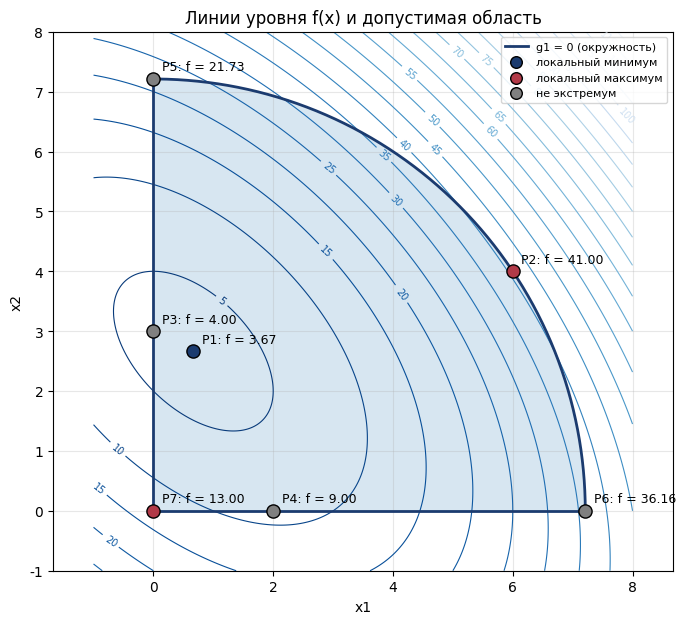

In [11]:
fn = sp.lambdify(X, f, "numpy")
r = np.sqrt(52)
a = np.linspace(-1, 8, 400)
A1, A2 = np.meshgrid(a, a)
F = fn(A1, A2)
inside = (A1**2 + A2**2 <= 52) & (A1 >= 0) & (A2 >= 0)

plt.figure(figsize=(8, 7))
cs = plt.contour(A1, A2, F, levels=25, cmap="Blues_r", linewidths=0.8)
plt.clabel(cs, fontsize=7, fmt="%.0f")
plt.contourf(A1, A2, inside, levels=[0.5, 1.5], colors=[BLUE_LIGHT], alpha=0.35)
t = np.linspace(0, np.pi / 2, 200)
plt.plot(r * np.cos(t), r * np.sin(t), color=BLUE_DARK, lw=2, label="g1 = 0 (окружность)")
plt.plot([0, 0], [0, r], color=BLUE_DARK, lw=2)
plt.plot([0, r], [0, 0], color=BLUE_DARK, lw=2)

colors = {"локальный минимум": BLUE_DARK, "локальный максимум": RED, "не экстремум": "gray"}
for i, (name, row) in enumerate(final.iterrows()):
    plt.scatter(row["x1"], row["x2"], s=90, color=colors[row["тип"]], edgecolor="black", zorder=5)
    plt.annotate(f"{name}: f = {row['f(x)']:.2f}", (row["x1"], row["x2"]),
                 textcoords="offset points", xytext=(6, 6), fontsize=9)
for t_name, c in colors.items():
    plt.scatter([], [], color=c, edgecolor="black", s=70, label=t_name)
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Линии уровня f(x) и допустимая область")
plt.legend(loc="upper right", fontsize=8)
plt.axis("equal")
plt.xlim(-1, 8)
plt.ylim(-1, 8)
plt.grid(alpha=0.3)
plt.show()

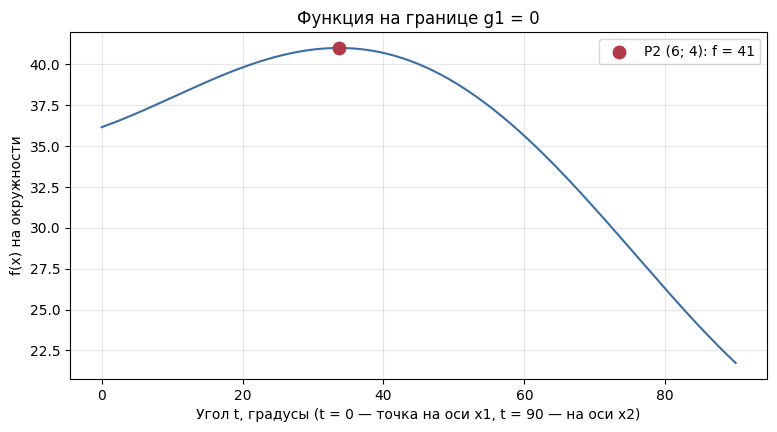

In [12]:
# значения функции на дуге окружности x1 = r cos t, x2 = r sin t
t = np.linspace(0, np.pi / 2, 400)
f_arc = fn(r * np.cos(t), r * np.sin(t))
t_max = np.arctan2(4, 6)

plt.figure(figsize=(9, 4.5))
plt.plot(np.degrees(t), f_arc, color=BLUE)
plt.scatter(np.degrees(t_max), fn(6, 4), color=RED, s=80, zorder=5, label="P2 (6; 4): f = 41")
plt.xlabel("Угол t, градусы (t = 0 — точка на оси x1, t = 90 — на оси x2)")
plt.ylabel("f(x) на окружности")
plt.title("Функция на границе g1 = 0")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

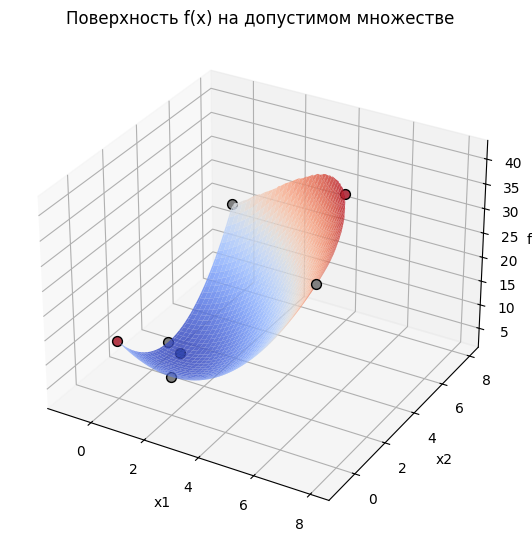

In [13]:
# поверхность функции над допустимой областью
fig = plt.figure(figsize=(9, 6.5))
ax = fig.add_subplot(projection="3d")
F_in = np.where(inside, F, np.nan)
ax.plot_surface(A1, A2, F_in, cmap="coolwarm", alpha=0.85, linewidth=0)
for name, row in final.iterrows():
    ax.scatter(row["x1"], row["x2"], row["f(x)"], color=colors[row["тип"]], s=50, edgecolor="black")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("f(x)")
ax.set_title("Поверхность f(x) на допустимом множестве")
plt.show()

## 9. Численная проверка

Проверим результат численным методом SLSQP из библиотеки SciPy: ищем минимум $f$ и минимум $-f$ (то есть максимум $f$) из нескольких начальных точек.

In [14]:
cons = [{"type": "ineq", "fun": lambda x: 52 - x[0]**2 - x[1]**2},
        {"type": "ineq", "fun": lambda x: x[0]},
        {"type": "ineq", "fun": lambda x: x[1]}]
f_num = lambda x: fn(x[0], x[1])

starts = [(1, 1), (5, 1), (1, 5), (0.1, 0.1), (6.5, 2)]
for x0 in starts:
    res_min = minimize(f_num, x0, constraints=cons, method="SLSQP")
    res_max = minimize(lambda x: -f_num(x), x0, constraints=cons, method="SLSQP")
    print(f"старт {x0}: min в ({res_min.x[0]:.4f}; {res_min.x[1]:.4f}), f = {res_min.fun:.4f} | "
          f"max в ({res_max.x[0]:.4f}; {res_max.x[1]:.4f}), f = {-res_max.fun:.4f}")

старт (1, 1): min в (0.6667; 2.6667), f = 3.6667 | max в (0.0000; -0.0000), f = 13.0000
старт (5, 1): min в (0.6667; 2.6667), f = 3.6667 | max в (6.0000; 4.0000), f = 41.0000
старт (1, 5): min в (0.6667; 2.6667), f = 3.6667 | max в (6.0000; 4.0000), f = 41.0000
старт (0.1, 0.1): min в (0.6667; 2.6667), f = 3.6667 | max в (0.0000; 0.0000), f = 13.0000
старт (6.5, 2): min в (0.6662; 2.6665), f = 3.6667 | max в (6.0000; 4.0001), f = 41.0000


## 10. Выводы

1. Исследована функция f(x) = (x1 − 2)² + (x2 − 3)² + x1·x2 на множестве X — четверти круга x1² + x2² ≤ 52, x1 ≥ 0, x2 ≥ 0. Матрица Гессе функции [[2, 1], [1, 2]] положительно определена (собственные значения 1 и 3), то есть функция выпуклая.
2. Случай λ0 = 0 не дал ненулевых решений — все точки регулярные, поэтому задача решалась с классической функцией Лагранжа (λ0 = 1). Перебор активных ограничений дал 7 допустимых стационарных точек.
3. Условия второго порядка проверены двумя способами — через второй дифференциал функции Лагранжа на касательном подпространстве и через окаймлённую матрицу Гессе (критерий Сильвестра, условия первого порядка при l = n). Оба способа дали одинаковый результат:
   - P1 (2/3; 8/3) — локальный минимум, f = 11/3 ≈ 3,667 (он же глобальный минимум);
   - P2 (6; 4) на окружности — локальный максимум, f = 41 (глобальный максимум);
   - P7 (0; 0) — локальный максимум, f = 13;
   - P3 (0; 3), P4 (2; 0), P5 (0; 7,211), P6 (7,211; 0) — не экстремумы: у P3 и P4 знак множителя говорит о максимуме, а второй дифференциал положителен; у P5 и P6 множители разных знаков.
4. Все найденные точки допустимы: в каждой точке g1, g2, g3 ≤ 0.
5. Графики (линии уровня, функция на окружности, поверхность) и численный метод SLSQP подтверждают результат: из разных начальных точек минимум всегда находится в (0,667; 2,667), а максимум — в (6; 4) или в локальном максимуме (0; 0).